# Solving CartPole with reinforcement learning — four algorithms, from scratch

CartPole is the *hello world* of RL: balance a pole on a moving cart by pushing it left or
right. The state is 4 numbers (cart position & velocity, pole angle & angular velocity), the
action is binary (push left / right), and you get **+1 reward per timestep the pole stays up**,
capped at **500**. So a return of 500 is a perfect episode, and a random policy scores ~20.

This notebook implements **four RL algorithms by hand** in PyTorch on the Gymnasium CartPole
environment — no `stable-baselines3`, so the actual learning rule is visible in each case.
They're ordered to tell a story about how modern policy-gradient RL was built up:

| # | Algorithm | Family | The idea it adds |
|---|-----------|--------|------------------|
| 1 | **REINFORCE** | policy gradient (Monte Carlo) | push up log-prob of actions ∝ return; baseline for variance |
| 2 | **A2C** | actor-critic (on-policy) | learned critic → replace return with **advantage**; bootstrap with GAE |
| 3 | **DQN** | value-based (off-policy) | learn Q(s,a); **replay buffer + target network** for stability |
| 4 | **PPO** | actor-critic (on-policy) | **clipped trust region** → stable multi-epoch updates |

> **Why these four:** REINFORCE → A2C → PPO is the policy-gradient lineage, and PPO's clipped
> surrogate is *exactly* the objective used in RLHF/GRPO for LLMs. DQN is the value-based
> counterpoint — a completely different way to solve the same task. Seeing both families on
> one tiny environment is the fastest way to internalise the tradeoffs.

**Runtime:** everything runs on **CPU in a few minutes total** (CartPole nets are tiny; no GPU
needed). Each algorithm has a config dataclass at the top so you can experiment. All four are
evaluated the same honest way — periodic *deterministic* rollouts, keeping the best checkpoint —
because training return is noisy and (for DQN especially) the last step is often not the best.

In [1]:
# === Dependencies ===============================================================
# Gymnasium is the maintained successor to OpenAI Gym (the original `gym` package is no
# longer maintained). The CartPole environment and physics are identical; only the package
# name and a couple of API details changed -- see the next cell.
%pip install -q gymnasium "torch>=2.0" matplotlib numpy
print("dependencies installed")

dependencies installed


In [2]:
# === Shared scaffolding =========================================================
# Everything the four algorithms reuse: networks, environment helpers, evaluation,
# GAE, and plotting. Keeping these here means each algorithm cell shows only the
# learning rule itself, not the boilerplate.
import math, random, time, copy
from dataclasses import dataclass, field
from collections import deque
from typing import Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import gymnasium as gym
import matplotlib.pyplot as plt

DEVICE = "cpu"   # CartPole nets are tiny; CPU is faster than GPU here (no transfer overhead)
ENV_ID = "CartPole-v1"   # 4-dim continuous state, 2 discrete actions, max return 500

def set_seed(s: int):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

def make_env(seed: Optional[int] = None):
    env = gym.make(ENV_ID)
    if seed is not None:
        env.reset(seed=seed)
        env.action_space.seed(seed)
    return env

# --- networks ---------------------------------------------------------------
class MLP(nn.Module):
    # Small 2-hidden-layer trunk; reused for policies, value functions and Q-functions.
    def __init__(self, in_dim, out_dim, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, out_dim),
        )
    def forward(self, x):
        return self.net(x)

class CategoricalPolicy(nn.Module):
    # Maps state -> logits over the 2 discrete actions. Gives a torch Categorical so we
    # get log_prob and entropy for free.
    def __init__(self, obs_dim, n_act, hidden=128):
        super().__init__()
        self.body = MLP(obs_dim, n_act, hidden)
    def dist(self, obs):
        return torch.distributions.Categorical(logits=self.body(obs))
    def forward(self, obs):
        return self.body(obs)

# --- GAE (shared by A2C and PPO) --------------------------------------------
def compute_gae(rewards, values, dones, last_value, gamma=0.99, lam=0.95):
    # Generalized Advantage Estimation. `values` are V(s_t) for the collected steps;
    # `last_value` is V(s_T) used to bootstrap the tail. Returns advantages and returns
    # (= advantages + values), both length T. dones[t]=1 means s_{t+1} was terminal.
    T = len(rewards)
    adv = np.zeros(T, dtype=np.float32)
    last_gae = 0.0
    for t in reversed(range(T)):
        next_v = last_value if t == T - 1 else values[t + 1]
        next_nonterminal = 1.0 - dones[t]
        delta = rewards[t] + gamma * next_v * next_nonterminal - values[t]   # TD error
        last_gae = delta + gamma * lam * next_nonterminal * last_gae
        adv[t] = last_gae
    returns = adv + np.asarray(values, dtype=np.float32)
    return adv, returns

# --- evaluation (the honest metric) -----------------------------------------
@torch.no_grad()
def evaluate_policy(select_action, n_episodes=20, seed=1000):
    # select_action(obs_np) -> int. Runs greedy/deterministic episodes on fresh seeds and
    # returns mean/std return. Training reward is noisy; this is what we trust.
    env = make_env()
    returns = []
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=seed + ep)
        done = False; total = 0.0
        while not done:
            a = select_action(obs)
            obs, r, term, trunc, _ = env.step(a)
            done = term or trunc
            total += r
        returns.append(total)
    env.close()
    return float(np.mean(returns)), float(np.std(returns))

# --- best-checkpoint tracking -----------------------------------------------
# All four algorithms are evaluated the same way: every so often we run a deterministic
# eval and remember the BEST network seen. This is honest (it's the policy you'd actually
# deploy) and it removes the "we happened to stop on a bad step" artifact -- which matters
# a lot for DQN, whose performance oscillates during training.
def track_best(history, greedy_fn, acting_module, step, n_episodes=10):
    m, _ = evaluate_policy(greedy_fn, n_episodes=n_episodes)
    history.setdefault("eval_points", []).append((step, m))
    if m >= history.get("best_eval", -1e9):
        history["best_eval"] = m
        history["best_state"] = copy.deepcopy(acting_module.state_dict())
    return m

# --- plotting ---------------------------------------------------------------
def smooth(x, k=20):
    if len(x) < k:
        return np.asarray(x, dtype=float)
    c = np.cumsum(np.insert(np.asarray(x, dtype=float), 0, 0))
    return (c[k:] - c[:-k]) / k

def plot_curve(history, title, solved=475):
    ep_r = history["episode_returns"]
    plt.figure(figsize=(9, 4.5))
    plt.plot(ep_r, alpha=0.25, label="episode return (train)")
    sm = smooth(ep_r, 20)
    plt.plot(range(len(ep_r) - len(sm), len(ep_r)), sm, lw=2, label="20-ep moving avg")
    plt.axhline(solved, ls="--", color="green", alpha=0.7, label=f"solved (~{solved})")
    plt.axhline(500, ls=":", color="gray", alpha=0.5, label="max (500)")
    plt.title(title + (f"   |   best greedy eval: {history.get('best_eval', float('nan')):.0f}"
                       if "best_eval" in history else ""))
    plt.xlabel("episode"); plt.ylabel("return")
    plt.legend(loc="lower right"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print("common scaffolding loaded | env:", ENV_ID, "| device:", DEVICE)

common scaffolding loaded | env: CartPole-v1 | device: cpu


## The environment: CartPole-v1 (and a note on Gym vs Gymnasium)

You asked for "OpenAI Gym". The original `openai/gym` is deprecated and now lives on as
**Gymnasium** (`pip install gymnasium`, `import gymnasium as gym`) — same environments, same
physics, actively maintained. The one thing to know is that the **step/reset API changed**,
and almost every old tutorial online still uses the old form:

```python
# OLD OpenAI Gym (<=0.21):
obs = env.reset()                       # returns obs only
obs, reward, done, info = env.step(a)   # 4-tuple; `done` mixes failure and time-limit

# NEW Gymnasium (used in this notebook):
obs, info = env.reset(seed=0)                          # returns (obs, info)
obs, reward, terminated, truncated, info = env.step(a) # 5-tuple
done = terminated or truncated
```

That `terminated` vs `truncated` split matters for RL correctness: **`terminated`** means a
real failure (pole fell / cart left the track) — the value of the next state is genuinely 0.
**`truncated`** means we hit the 500-step time limit — the episode was still "alive", so we
should *bootstrap* its value, not treat it as terminal. Throughout this notebook we bootstrap
on `truncated` but not on `terminated` (look for `done = 1.0 if term else 0.0` in the code).

CartPole specifics: state ∈ ℝ⁴ `[x, ẋ, θ, θ̇]`, actions `{0:left, 1:right}`, reward `+1`
per step, episode ends at failure or 500 steps. **Solved ≈ average return 475+.**

In [3]:
# === Anchor: how good is a random policy? =======================================
# Always establish the floor before training. A random CartPole policy keeps the pole up
# for ~20 steps. Everything below has to beat this by a lot.
def random_baseline(n=20):
    env = make_env()
    rs = []
    for ep in range(n):
        obs, _ = env.reset(seed=5000 + ep); done = False; total = 0.0
        while not done:
            obs, r, term, trunc, _ = env.step(env.action_space.sample())
            done = term or trunc; total += r
        rs.append(total)
    env.close()
    return np.mean(rs), np.std(rs)

_m, _s = random_baseline()
print(f"random policy return: {_m:.1f} +/- {_s:.1f}   (max possible = 500)")

random policy return: 21.5 +/- 9.1   (max possible = 500)


## 1 · REINFORCE — the simplest policy gradient

Directly optimise the policy: play full episodes, then for every action increase its
log-probability in proportion to the **return that followed it**. Good actions (high return)
get reinforced; bad ones get suppressed. No value function, no bootstrapping.

**What to watch:** the learning curve is *jagged*. REINFORCE is unbiased but high-variance —
a single lucky or unlucky episode swings the gradient hard. The `normalize_returns` flag
(subtracting the mean return) is the cheapest variance fix and the conceptual seed of the
"advantage" that the next algorithms make central. Expect it to eventually solve CartPole but
to wobble a lot on the way (and sometimes regress) — which is the whole motivation for A2C.

In [4]:
# === Algorithm 1: REINFORCE (Monte Carlo policy gradient) =======================
# The simplest policy gradient. Play whole episodes, compute the discounted return-to-go
# G_t for each step, and push up the log-probability of actions in proportion to G_t:
#
#     grad J = E[ sum_t  grad log pi(a_t|s_t) * G_t ]
#
# High variance, because G_t is a noisy Monte Carlo estimate. The standard fix is a
# baseline: subtract the mean return (here we whiten G_t). That doesn't change the
# expected gradient but cuts variance a lot -- this is the seed of "advantage".

@dataclass
class ReinforceCfg:
    episodes: int = 800
    gamma: float = 0.99
    lr: float = 7e-3
    hidden: int = 128
    normalize_returns: bool = True   # the baseline / variance-reduction trick
    entropy_coef: float = 0.0
    eval_every: int = 100            # episodes between greedy evals (keep best checkpoint)
    seed: int = 0
    log_every: int = 100

def returns_to_go(rewards, gamma):
    g = 0.0; out = []
    for r in reversed(rewards):
        g = r + gamma * g
        out.append(g)
    return list(reversed(out))

def train_reinforce(cfg: ReinforceCfg):
    set_seed(cfg.seed)
    env = make_env(seed=cfg.seed)
    obs_dim = env.observation_space.shape[0]; n_act = env.action_space.n
    policy = CategoricalPolicy(obs_dim, n_act, cfg.hidden).to(DEVICE)
    opt = torch.optim.Adam(policy.parameters(), lr=cfg.lr)

    history = {"episode_returns": []}

    @torch.no_grad()
    def greedy(o):                                         # deterministic action for eval
        logits = policy(torch.as_tensor(o, dtype=torch.float32, device=DEVICE))
        return int(logits.argmax().item())

    for ep in range(cfg.episodes):
        obs, _ = env.reset()
        logps, ents, rews = [], [], []
        done = False
        while not done:
            obs_t = torch.as_tensor(obs, dtype=torch.float32, device=DEVICE)
            dist = policy.dist(obs_t)
            a = dist.sample()
            logps.append(dist.log_prob(a))
            ents.append(dist.entropy())
            obs, r, term, trunc, _ = env.step(int(a.item()))
            rews.append(r); done = term or trunc
        history["episode_returns"].append(sum(rews))

        # ---- the REINFORCE update ----
        G = torch.tensor(returns_to_go(rews, cfg.gamma), dtype=torch.float32, device=DEVICE)
        if cfg.normalize_returns and len(G) > 1:
            G = (G - G.mean()) / (G.std() + 1e-8)         # baseline: zero-mean, unit-var
        logp = torch.stack(logps); ent = torch.stack(ents)
        loss = -(logp * G).sum() - cfg.entropy_coef * ent.sum()
        opt.zero_grad(); loss.backward(); opt.step()

        if (ep + 1) % cfg.log_every == 0:
            recent = np.mean(history["episode_returns"][-cfg.log_every:])
            print(f"  ep {ep+1:4d} | avg return (last {cfg.log_every}): {recent:6.1f}")
        if (ep + 1) % cfg.eval_every == 0:
            track_best(history, greedy, policy, ep + 1)
    env.close()

    if history.get("best_state") is not None:
        policy.load_state_dict(history["best_state"])
    history["select_action"] = greedy
    history["policy"] = policy
    return history

  ep  100 | avg return (last 100):   15.8
  ep  200 | avg return (last 100):   17.2
  ep  300 | avg return (last 100):   15.8
  ep  400 | avg return (last 100):   50.8
  ep  500 | avg return (last 100):  223.5
  ep  600 | avg return (last 100):   50.0
  ep  700 | avg return (last 100):   93.2
  ep  800 | avg return (last 100):  104.6

best deterministic eval: 241 / 500


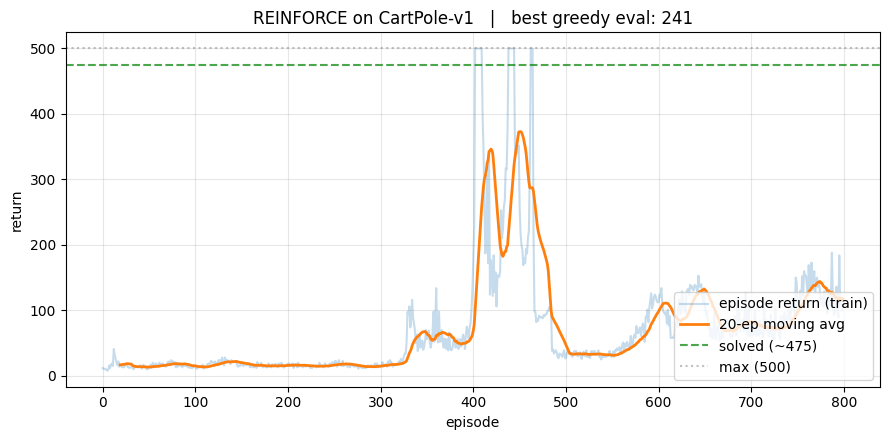

In [5]:
# Train REINFORCE (~30-40s on CPU). Reaches return 500, but watch the variance.
h_reinforce = train_reinforce(ReinforceCfg(seed=0))
print(f"\nbest deterministic eval: {h_reinforce['best_eval']:.0f} / 500")
plot_curve(h_reinforce, "REINFORCE on CartPole-v1")

## 2 · A2C — add a critic, learn from advantages

A2C keeps the policy gradient but introduces a **critic** V(s) trained to predict the return.
The policy is now updated using the **advantage** A = (bootstrapped return) − V(s): how much
better an action did than the critic expected. Two wins over REINFORCE:

- **Lower variance** — V(s) is a state-dependent baseline (far better than a global mean).
- **Bootstrapping (GAE)** — we learn from short rollouts instead of waiting for full episodes,
  trading a little bias for a lot less variance via the `lam` knob.

**What to watch:** smoother and more sample-efficient than REINFORCE, but still **on-policy and
un-clipped**, so a too-large update can still destabilise it — you'll see dips. That residual
instability is precisely what PPO fixes.

In [6]:
# === Algorithm 2: A2C (Advantage Actor-Critic) ==================================
# REINFORCE's weakness is variance. A2C adds a learned critic V(s) and replaces the raw
# return G_t with an ADVANTAGE A_t = (return estimate) - V(s_t). The critic acts as a
# state-dependent baseline, and bootstrapping (GAE) lets us learn from partial rollouts
# instead of waiting for whole episodes.
#
#   actor loss   = -E[ log pi(a|s) * A ]          (A is detached -> no grad into critic)
#   critic loss  =  E[ (V(s) - return)^2 ]
#   total        =  actor + vf_coef*critic - ent_coef*entropy
#
# This is the bridge between REINFORCE and PPO: same advantage idea, but on-policy and
# without the trust-region clip that PPO will add next.

@dataclass
class A2CCfg:
    total_steps: int = 60_000
    rollout_steps: int = 256          # steps collected per update (can span episodes)
    gamma: float = 0.99
    lam: float = 0.95                 # GAE lambda
    lr: float = 3e-3
    hidden: int = 128
    vf_coef: float = 0.5
    ent_coef: float = 0.01
    max_grad_norm: float = 0.5
    eval_every: int = 5_000          # steps between greedy evals (keep best checkpoint)
    seed: int = 0
    log_every: int = 10_000

class ActorCritic(nn.Module):
    # Shared-free design: separate policy and value heads (simpler to read than a shared trunk).
    def __init__(self, obs_dim, n_act, hidden=128):
        super().__init__()
        self.policy = CategoricalPolicy(obs_dim, n_act, hidden)
        self.value = MLP(obs_dim, 1, hidden)
    def value_of(self, obs):
        return self.value(obs).squeeze(-1)

def train_a2c(cfg: A2CCfg):
    set_seed(cfg.seed)
    env = make_env(seed=cfg.seed)
    obs_dim = env.observation_space.shape[0]; n_act = env.action_space.n
    ac = ActorCritic(obs_dim, n_act, cfg.hidden).to(DEVICE)
    opt = torch.optim.Adam(ac.parameters(), lr=cfg.lr)

    history = {"episode_returns": []}
    obs, _ = env.reset()
    ep_ret = 0.0; steps = 0

    @torch.no_grad()
    def greedy(o):
        logits = ac.policy(torch.as_tensor(o, dtype=torch.float32, device=DEVICE))
        return int(logits.argmax().item())

    while steps < cfg.total_steps:
        # ---- collect a rollout ----
        obs_buf, act_buf, logp_buf, rew_buf, val_buf, done_buf = [], [], [], [], [], []
        for _ in range(cfg.rollout_steps):
            obs_t = torch.as_tensor(obs, dtype=torch.float32, device=DEVICE)
            dist = ac.policy.dist(obs_t)
            a = dist.sample()
            v = ac.value_of(obs_t)
            nobs, r, term, trunc, _ = env.step(int(a.item()))
            done = term or trunc

            obs_buf.append(obs); act_buf.append(int(a.item()))
            logp_buf.append(float(dist.log_prob(a).item()))
            rew_buf.append(r); val_buf.append(float(v.item()))
            # for bootstrapping we only treat TRUE termination as terminal, not time-limit
            done_buf.append(1.0 if term else 0.0)

            obs = nobs; ep_ret += r; steps += 1
            if done:
                history["episode_returns"].append(ep_ret); ep_ret = 0.0
                obs, _ = env.reset()

        # ---- advantages via GAE ----
        with torch.no_grad():
            last_v = float(ac.value_of(torch.as_tensor(obs, dtype=torch.float32, device=DEVICE)).item())
        adv, ret = compute_gae(rew_buf, val_buf, done_buf, last_v, cfg.gamma, cfg.lam)
        adv = torch.as_tensor((adv - adv.mean()) / (adv.std() + 1e-8), device=DEVICE)
        ret = torch.as_tensor(ret, device=DEVICE)

        obs_t = torch.as_tensor(np.array(obs_buf), dtype=torch.float32, device=DEVICE)
        act_t = torch.as_tensor(act_buf, dtype=torch.long, device=DEVICE)

        # ---- single on-policy update ----
        dist = ac.policy.dist(obs_t)
        logp = dist.log_prob(act_t)
        ent = dist.entropy().mean()
        v = ac.value_of(obs_t)

        actor_loss = -(logp * adv).mean()                 # advantage already detached (numpy)
        critic_loss = F.mse_loss(v, ret)
        loss = actor_loss + cfg.vf_coef * critic_loss - cfg.ent_coef * ent

        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(ac.parameters(), cfg.max_grad_norm)
        opt.step()

        if steps % cfg.log_every < cfg.rollout_steps and history["episode_returns"]:
            recent = np.mean(history["episode_returns"][-30:])
            print(f"  step {steps:6d} | avg return (last 30 ep): {recent:6.1f}")
        if steps % cfg.eval_every < cfg.rollout_steps:
            track_best(history, greedy, ac.policy, steps)
    env.close()

    if history.get("best_state") is not None:
        ac.policy.load_state_dict(history["best_state"])
    history["select_action"] = greedy
    history["model"] = ac
    return history

  step  10240 | avg return (last 30 ep):  161.2
  step  20224 | avg return (last 30 ep):  132.1
  step  30208 | avg return (last 30 ep):  291.6
  step  40192 | avg return (last 30 ep):  302.0
  step  50176 | avg return (last 30 ep):  444.5
  step  60160 | avg return (last 30 ep):   23.6

best deterministic eval: 500 / 500


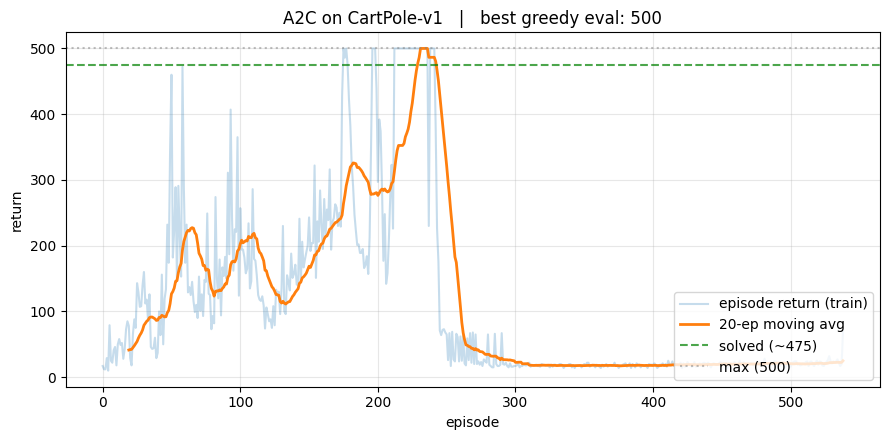

In [7]:
# Train A2C (~25s on CPU).
h_a2c = train_a2c(A2CCfg(seed=0))
print(f"\nbest deterministic eval: {h_a2c['best_eval']:.0f} / 500")
plot_curve(h_a2c, "A2C on CartPole-v1")

## 3 · DQN — the value-based alternative

A completely different family. Instead of a policy, learn the **action-value** Q(s,a) — the
expected return of taking action a in state s — and act greedily w.r.t. it. DQN is **off-policy**:
it learns from a **replay buffer** of past transitions, reusing each experience many times,
which makes it far more sample-efficient per environment step. The two tricks that made deep
Q-learning stable (DQN, 2015):

- **Target network** — a slow copy of Q provides the bootstrap target, so we aren't chasing a
  moving goal. Here we use a soft (Polyak) update every step.
- **ε-greedy with decay** — explore randomly early, exploit Q as it becomes reliable.

**What to watch:** DQN is notoriously **unstable on CartPole** — it often reaches 500 and then
*collapses*, oscillating between great and poor policies (you'll see this clearly in the eval
points printed during training). This is exactly why best-checkpointing matters, and a sharp
contrast to PPO's monotone curve. It's also slower in wall-clock here because it does a gradient
step every environment step.

In [8]:
# === Algorithm 3: DQN (Deep Q-Network) ==========================================
# A different family entirely: value-based, off-policy. Instead of a policy, we learn the
# action-value Q(s,a) and act greedily w.r.t. it. Three ingredients make the deep version
# stable (all from the 2015 DQN paper):
#   1. Replay buffer  -> breaks correlation between consecutive samples, reuses data
#   2. Target network -> a slow copy of Q used for the bootstrap target (stops chasing
#                        a moving target)
#   3. epsilon-greedy -> exploration that decays as Q gets reliable
#
#   target = r + gamma * max_a' Q_target(s', a') * (1 - done)
#   loss   = Huber( Q(s,a) , target )

@dataclass
class DQNCfg:
    total_steps: int = 40_000
    gamma: float = 0.99
    lr: float = 1e-3
    hidden: int = 128
    buffer_size: int = 50_000
    batch_size: int = 128
    warmup: int = 1_000               # random steps before learning starts
    train_every: int = 1
    target_tau: float = 0.01          # soft target update (Polyak); 0 -> use hard sync
    target_sync_every: int = 500      # used only if target_tau == 0
    eps_start: float = 1.0
    eps_end: float = 0.02
    eps_decay_steps: int = 10_000
    eval_every: int = 2_000           # periodic greedy eval -> keep best checkpoint
    seed: int = 0
    log_every: int = 10_000

class ReplayBuffer:
    def __init__(self, capacity, obs_dim):
        self.cap = capacity; self.size = 0; self.ptr = 0
        self.obs  = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.nobs = np.zeros((capacity, obs_dim), dtype=np.float32)
        self.act  = np.zeros(capacity, dtype=np.int64)
        self.rew  = np.zeros(capacity, dtype=np.float32)
        self.done = np.zeros(capacity, dtype=np.float32)
    def add(self, o, a, r, no, d):
        i = self.ptr
        self.obs[i]=o; self.act[i]=a; self.rew[i]=r; self.nobs[i]=no; self.done[i]=d
        self.ptr = (self.ptr + 1) % self.cap; self.size = min(self.size + 1, self.cap)
    def sample(self, n):
        idx = np.random.randint(0, self.size, size=n)
        to = lambda x: torch.as_tensor(x[idx], device=DEVICE)
        return to(self.obs), to(self.act), to(self.rew), to(self.nobs), to(self.done)

def train_dqn(cfg: DQNCfg):
    set_seed(cfg.seed)
    env = make_env(seed=cfg.seed)
    obs_dim = env.observation_space.shape[0]; n_act = env.action_space.n
    q = MLP(obs_dim, n_act, cfg.hidden).to(DEVICE)
    q_target = MLP(obs_dim, n_act, cfg.hidden).to(DEVICE)
    q_target.load_state_dict(q.state_dict())
    opt = torch.optim.Adam(q.parameters(), lr=cfg.lr)
    buf = ReplayBuffer(cfg.buffer_size, obs_dim)

    def epsilon(step):
        frac = min(1.0, step / cfg.eps_decay_steps)
        return cfg.eps_start + frac * (cfg.eps_end - cfg.eps_start)

    history = {"episode_returns": []}
    obs, _ = env.reset(); ep_ret = 0.0

    @torch.no_grad()
    def greedy(o):
        return int(q(torch.as_tensor(o, dtype=torch.float32, device=DEVICE)).argmax().item())

    for step in range(cfg.total_steps):
        eps = epsilon(step)
        if random.random() < eps or step < cfg.warmup:
            a = env.action_space.sample()
        else:
            with torch.no_grad():
                a = int(q(torch.as_tensor(obs, dtype=torch.float32, device=DEVICE)).argmax().item())
        nobs, r, term, trunc, _ = env.step(a)
        done = term or trunc
        buf.add(obs, a, r, nobs, 1.0 if term else 0.0)   # time-limit truncation != terminal
        obs = nobs; ep_ret += r
        if done:
            history["episode_returns"].append(ep_ret); ep_ret = 0.0
            obs, _ = env.reset()

        # ---- learn ----
        if step >= cfg.warmup and step % cfg.train_every == 0:
            o, ac_, rw, no, dn = buf.sample(cfg.batch_size)
            with torch.no_grad():
                target = rw + cfg.gamma * q_target(no).max(dim=1).values * (1.0 - dn)
            qsa = q(o).gather(1, ac_.unsqueeze(1)).squeeze(1)
            loss = F.smooth_l1_loss(qsa, target)          # Huber: robust to outlier TD errors
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(q.parameters(), 10.0)
            opt.step()

            # ---- target update ----
            if cfg.target_tau > 0:                        # soft (Polyak) update every step
                with torch.no_grad():
                    for tp, p in zip(q_target.parameters(), q.parameters()):
                        tp.mul_(1 - cfg.target_tau).add_(cfg.target_tau * p)
            elif step % cfg.target_sync_every == 0:       # hard sync
                q_target.load_state_dict(q.state_dict())

        if (step + 1) % cfg.log_every == 0 and history["episode_returns"]:
            recent = np.mean(history["episode_returns"][-30:])
            print(f"  step {step+1:6d} | eps {eps:.2f} | avg return (last 30 ep): {recent:6.1f}")

        if step >= cfg.warmup and (step + 1) % cfg.eval_every == 0:
            track_best(history, greedy, q, step + 1)
    env.close()

    if history.get("best_state") is not None:    # deploy the best network, not the last
        q.load_state_dict(history["best_state"])
    history["select_action"] = greedy
    history["q"] = q
    return history

  step  10000 | eps 0.02 | avg return (last 30 ep):  164.7
  step  20000 | eps 0.02 | avg return (last 30 ep):  402.6
  step  30000 | eps 0.02 | avg return (last 30 ep):  165.0
  step  40000 | eps 0.02 | avg return (last 30 ep):  283.8

eval scores during training (step, return): [(2000, 245), (4000, 159), (6000, 223), (8000, 132), (10000, 500), (12000, 118), (14000, 131), (16000, 500), (18000, 101), (20000, 118), (22000, 102), (24000, 109), (26000, 93), (28000, 73), (30000, 93), (32000, 121), (34000, 169), (36000, 500), (38000, 91), (40000, 82)]
best deterministic eval: 500 / 500


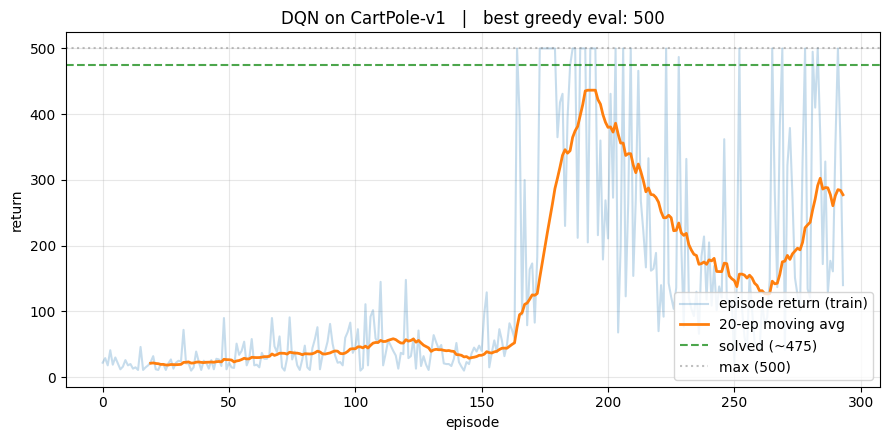

In [9]:
# Train DQN (~60-70s on CPU). Note how the periodic eval scores swing wildly -- DQN finds a
# 500 policy and then drifts off it. Best-checkpointing keeps the good one.
h_dqn = train_dqn(DQNCfg(seed=0))
print(f"\neval scores during training (step, return): {[(s, round(v)) for s, v in h_dqn['eval_points']]}")
print(f"best deterministic eval: {h_dqn['best_eval']:.0f} / 500")
plot_curve(h_dqn, "DQN on CartPole-v1")

## 4 · PPO — the modern default (and the GRPO ancestor)

PPO keeps A2C's advantage/critic setup but solves the instability with a **clipped surrogate
objective**. It computes the probability ratio between the new and old policy and *clips* it,
so no single update can move the policy outside a trust region — which lets PPO safely take
**many gradient epochs on the same rollout** (sample-efficient *and* stable):

$$L^{\text{clip}} = \mathbb{E}\big[\min(r_t A_t,\ \text{clip}(r_t, 1-\epsilon, 1+\epsilon)A_t)\big],\quad r_t=\frac{\pi_{\text{new}}(a_t|s_t)}{\pi_{\text{old}}(a_t|s_t)}$$

If that objective looks familiar, it should: **it's the same clipped surrogate as in the GRPO
notebook.** The only structural difference is where the advantage comes from — PPO uses a
learned critic + GAE on a single trajectory; GRPO throws away the critic and computes a
*group-relative* advantage from the spread of rewards over many completions of one prompt.
Same trust-region machinery, different baseline. The next cell makes that mapping explicit.

**What to watch:** the smoothest, most reliable curve of the four — a near-monotone climb to
500 with little regression. That stability is why PPO became the workhorse for both control and
LLM post-training.

In [10]:
# === Algorithm 4: PPO (Proximal Policy Optimization) ============================
# The modern default, and -- not coincidentally -- the direct ancestor of GRPO. PPO keeps
# A2C's advantage idea but fixes its instability with a CLIPPED surrogate that stops any
# single update from moving the policy too far:
#
#   ratio_t   = pi_new(a|s) / pi_old(a|s)
#   L_clip    = E[ min( ratio_t * A_t , clip(ratio_t, 1-eps, 1+eps) * A_t ) ]
#
# That objective is exactly the one in the GRPO notebook. The ONLY structural difference:
#   * PPO here gets A_t from a learned critic V(s) via GAE (single-trajectory RL).
#   * GRPO drops the critic and gets A_t from the spread of rewards across a GROUP of
#     completions for the same prompt (group-relative advantage).
# Same trust-region clip, same multi-epoch reuse of a rollout; different baseline. CartPole
# is the clean place to see the machinery before it goes to LLMs.

@dataclass
class PPOCfg:
    total_steps: int = 60_000
    rollout_steps: int = 2_048
    gamma: float = 0.99
    lam: float = 0.95
    clip: float = 0.2                 # the epsilon in the clipped surrogate
    lr: float = 3e-4
    hidden: int = 64
    epochs: int = 10                  # PPO reuses each rollout for several passes
    minibatch_size: int = 64
    vf_coef: float = 0.5
    ent_coef: float = 0.0
    max_grad_norm: float = 0.5
    clip_value: bool = True           # also clip the value-function update (PPO2 detail)
    eval_every: int = 5_000
    seed: int = 0
    log_every: int = 10_000

def train_ppo(cfg: PPOCfg):
    set_seed(cfg.seed)
    env = make_env(seed=cfg.seed)
    obs_dim = env.observation_space.shape[0]; n_act = env.action_space.n
    ac = ActorCritic(obs_dim, n_act, cfg.hidden).to(DEVICE)   # reuse A2C's actor-critic
    opt = torch.optim.Adam(ac.parameters(), lr=cfg.lr)

    history = {"episode_returns": []}
    obs, _ = env.reset(); ep_ret = 0.0; steps = 0

    @torch.no_grad()
    def greedy(o):
        logits = ac.policy(torch.as_tensor(o, dtype=torch.float32, device=DEVICE))
        return int(logits.argmax().item())

    while steps < cfg.total_steps:
        # ---- 1. collect a rollout under the CURRENT (old) policy ----
        O, A, LP, R, V, D = [], [], [], [], [], []
        for _ in range(cfg.rollout_steps):
            obs_t = torch.as_tensor(obs, dtype=torch.float32, device=DEVICE)
            with torch.no_grad():
                dist = ac.policy.dist(obs_t); a = dist.sample()
                v = ac.value_of(obs_t)
            nobs, r, term, trunc, _ = env.step(int(a.item()))
            O.append(obs); A.append(int(a.item())); LP.append(float(dist.log_prob(a).item()))
            R.append(r); V.append(float(v.item())); D.append(1.0 if term else 0.0)
            obs = nobs; ep_ret += r; steps += 1
            if term or trunc:
                history["episode_returns"].append(ep_ret); ep_ret = 0.0
                obs, _ = env.reset()

        # ---- 2. GAE advantages + returns ----
        with torch.no_grad():
            last_v = float(ac.value_of(torch.as_tensor(obs, dtype=torch.float32, device=DEVICE)).item())
        adv, ret = compute_gae(R, V, D, last_v, cfg.gamma, cfg.lam)

        O_t  = torch.as_tensor(np.array(O), dtype=torch.float32, device=DEVICE)
        A_t  = torch.as_tensor(A, dtype=torch.long, device=DEVICE)
        LP_t = torch.as_tensor(LP, dtype=torch.float32, device=DEVICE)
        adv_t = torch.as_tensor(adv, device=DEVICE)
        ret_t = torch.as_tensor(ret, device=DEVICE)
        V_t  = torch.as_tensor(V, dtype=torch.float32, device=DEVICE)
        adv_t = (adv_t - adv_t.mean()) / (adv_t.std() + 1e-8)

        # ---- 3. several epochs of minibatch updates on the SAME rollout ----
        n = cfg.rollout_steps
        idx = np.arange(n)
        for _ in range(cfg.epochs):
            np.random.shuffle(idx)
            for s in range(0, n, cfg.minibatch_size):
                mb = idx[s:s + cfg.minibatch_size]
                dist = ac.policy.dist(O_t[mb])
                new_logp = dist.log_prob(A_t[mb])
                ratio = torch.exp(new_logp - LP_t[mb])            # pi_new / pi_old

                # clipped policy surrogate (identical form to the GRPO loss)
                unclipped = ratio * adv_t[mb]
                clipped = torch.clamp(ratio, 1 - cfg.clip, 1 + cfg.clip) * adv_t[mb]
                policy_loss = -torch.min(unclipped, clipped).mean()

                # value loss (optionally clipped, PPO2 style)
                v_pred = ac.value_of(O_t[mb])
                if cfg.clip_value:
                    v_clipped = V_t[mb] + torch.clamp(v_pred - V_t[mb], -cfg.clip, cfg.clip)
                    v_loss = torch.max((v_pred - ret_t[mb])**2, (v_clipped - ret_t[mb])**2).mean()
                else:
                    v_loss = F.mse_loss(v_pred, ret_t[mb])

                ent = dist.entropy().mean()
                loss = policy_loss + cfg.vf_coef * v_loss - cfg.ent_coef * ent
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(ac.parameters(), cfg.max_grad_norm)
                opt.step()

        if steps % cfg.log_every < cfg.rollout_steps and history["episode_returns"]:
            recent = np.mean(history["episode_returns"][-30:])
            print(f"  step {steps:6d} | avg return (last 30 ep): {recent:6.1f}")
        if steps % cfg.eval_every < cfg.rollout_steps:
            track_best(history, greedy, ac.policy, steps)
    env.close()

    if history.get("best_state") is not None:
        ac.policy.load_state_dict(history["best_state"])
    history["select_action"] = greedy
    history["model"] = ac
    return history

  step  10240 | avg return (last 30 ep):   98.7
  step  20480 | avg return (last 30 ep):  211.3
  step  30720 | avg return (last 30 ep):  229.6
  step  40960 | avg return (last 30 ep):  258.3
  step  51200 | avg return (last 30 ep):  354.3
  step  61440 | avg return (last 30 ep):  312.8

eval scores during training (step, return): [(6144, 380), (10240, 382), (16384, 446), (20480, 453), (26624, 470), (30720, 494), (36864, 397), (40960, 448), (45056, 500), (51200, 436), (55296, 335), (61440, 193)]
best deterministic eval: 500 / 500


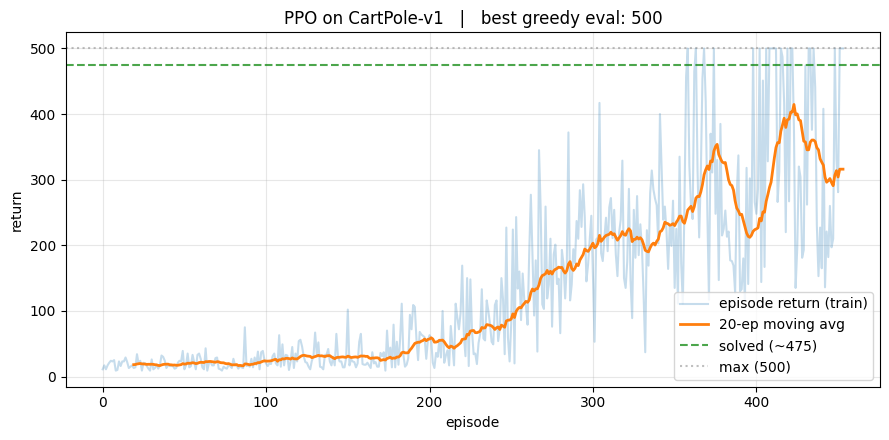

In [11]:
# Train PPO (~40s on CPU). Compare the smoothness of these eval scores to DQN's.
h_ppo = train_ppo(PPOCfg(seed=0))
print(f"\neval scores during training (step, return): {[(s, round(v)) for s, v in h_ppo['eval_points']]}")
print(f"best deterministic eval: {h_ppo['best_eval']:.0f} / 500")
plot_curve(h_ppo, "PPO on CartPole-v1")

## Comparing the four

All four solve CartPole (best deterministic eval ≈ 500), so the interesting question is *how*
they get there. The plot below puts every algorithm on a **common x-axis of environment steps**
— a fair sample-efficiency comparison — using a neat CartPole identity: since reward is +1 per
step, an episode's return *equals* its length in steps, so `cumsum(returns)` is the cumulative
environment-step count.

What you should see:
- **DQN** is usually the most **sample-efficient per env step** (off-policy replay reuses data)
  but the **least stable** (jagged, collapses).
- **PPO** is the **most stable** and reliable, at the cost of needing fresh on-policy rollouts.
- **A2C** sits between REINFORCE and PPO — advantages help, but no clip means wobble.
- **REINFORCE** is the noisiest — pure Monte Carlo variance.

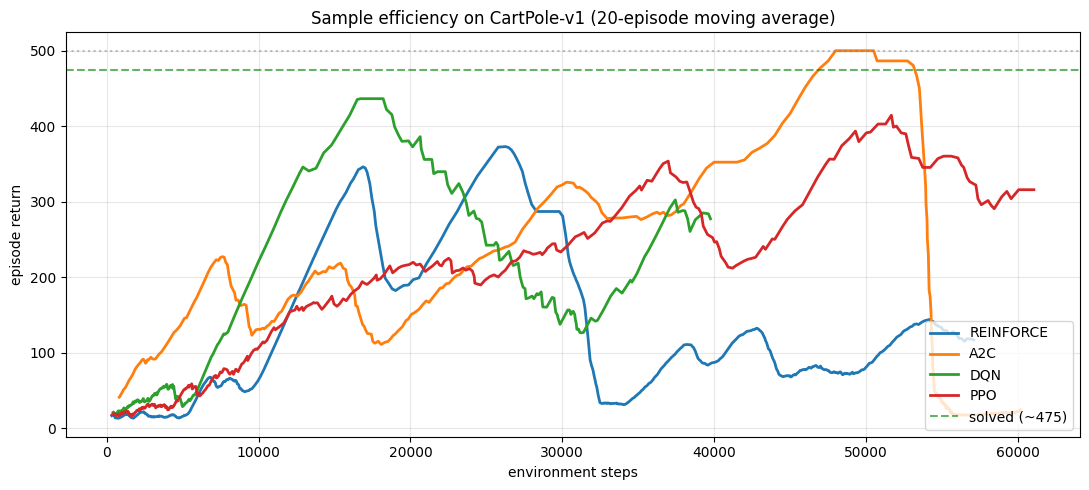

algorithm     best eval   env steps used   episodes
REINFORCE           241           57,082        800
A2C                 500           60,157        539
DQN                 500           39,759        294
PPO                 500           61,050        454


In [12]:
# === Sample-efficiency comparison ==============================================
# x-axis = cumulative environment steps (= cumsum of returns, since reward is +1/step).
runs = {"REINFORCE": h_reinforce, "A2C": h_a2c, "DQN": h_dqn, "PPO": h_ppo}

plt.figure(figsize=(11, 5))
for name, h in runs.items():
    ep_r = np.asarray(h["episode_returns"], dtype=float)
    steps = np.cumsum(ep_r)                       # cumulative env steps at each episode end
    sm = smooth(ep_r, 20)
    x = steps[len(steps) - len(sm):]
    plt.plot(x, sm, lw=2, label=name)
plt.axhline(475, ls="--", color="green", alpha=0.6, label="solved (~475)")
plt.axhline(500, ls=":", color="gray", alpha=0.5)
plt.title("Sample efficiency on CartPole-v1 (20-episode moving average)")
plt.xlabel("environment steps"); plt.ylabel("episode return")
plt.legend(loc="lower right"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# summary table
print(f"{'algorithm':12s} {'best eval':>10s} {'env steps used':>16s} {'episodes':>10s}")
for name, h in runs.items():
    total_steps = int(np.sum(h["episode_returns"]))
    print(f"{name:12s} {h['best_eval']:10.0f} {total_steps:16,d} {len(h['episode_returns']):10d}")

## From PPO here to GRPO for LLMs

The PPO you just ran and GRPO (the LLM RL algorithm) are the **same optimisation backbone**.
Lining them up:

| Piece | PPO on CartPole (this notebook) | GRPO on an LLM |
|-------|----------------------------------|----------------|
| "policy" | small MLP over 2 actions | the language model over next-token vocab |
| "action" | push left / right | generate a token |
| "trajectory" | one balancing episode | one full completion to a prompt |
| reward | +1 per step survived | verifiable reward on the final answer (RLVR) |
| **advantage source** | learned critic V(s) + **GAE** | **group-relative**: reward minus the mean over G completions of the same prompt (no critic) |
| objective | clipped surrogate $\min(rA, \text{clip}(r)A)$ | the **same** clipped surrogate |
| multi-epoch reuse | yes (PPO epochs) | yes (μ inner updates) |

So GRPO is, roughly, **"PPO with the critic deleted and replaced by a group baseline"** — which
is what makes it cheap enough to run on large models (no separate value network to train). Every
trick in the GRPO++ notebook — clip-higher, token-level loss, dynamic sampling, GSPO/CISPO — is a
modification *on top of this clipped objective*. CartPole is the clean, 3-minute place to build
the intuition before scaling the same idea to reasoning models.

## Where to go next

- **Harder control:** swap `ENV_ID` to `"LunarLander-v3"` (still discrete) or move to continuous
  control (`"Pendulum-v1"`, MuJoCo) — for continuous actions, PPO uses a Gaussian policy and you'd
  reach for **SAC/TD3** on the value-based side.
- **Stabilise / extend DQN:** add Double DQN (decouple action selection from evaluation),
  Dueling heads, or Prioritised Experience Replay — each is a small change to the DQN cell here.
- **Production libraries:** once you understand the mechanics, `stable-baselines3` or `cleanrl`
  give tuned, vectorised implementations. `cleanrl`'s single-file style is especially close in
  spirit to this notebook.
- **Vectorised envs:** `gym.make_vec(ENV_ID, num_envs=N)` collects rollouts from many copies in
  parallel — the biggest practical speedup for on-policy methods (A2C/PPO).
- **Back to LLMs:** the GRPO++ notebook is the same PPO objective applied to language models.